# Chapter 8: Applying Machine Learning to Sentiment Analysis

- NLP 

- Opinion Mining 

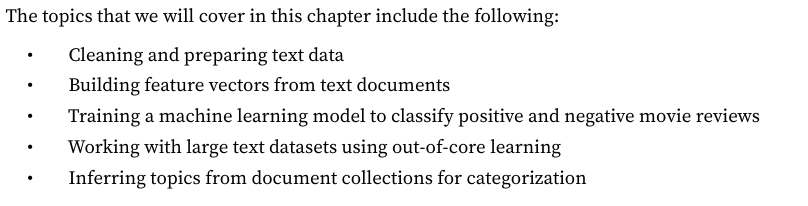

### Preparing the IMDb movie review data for text processing

In [47]:
from tqdm import tqdm 
import pandas as pd
import os 
import sys
 
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

In [39]:
basepath = "aclImdb"
labels = {"pos": 1, "neg": 0}

In [40]:
total_files = 0
for s in ("test", "train"):
    for l in ("pos", "neg"):
        path = os.path.join(basepath, s, l)
        if os.path.exists(path):
            total_files += len(os.listdir(path))

print(f"Total files to process: {total_files}")

Total files to process: 50000


In [41]:




pbar = tqdm(total=total_files, desc="Loading")

# Collect rows in a list
rows = []

for s in ("test", "train"): 
    for l in ("pos", "neg"):
        path = os.path.join(basepath, s, l)
        for file in sorted(os.listdir(path)):
            with open(os.path.join(path, file), "r", encoding="utf-8") as infile:
                txt = infile.read()
                rows.append([txt, labels[l]])   # collect row
                pbar.update(1)
         
pbar.close()

# Create DataFrame once at the end
df = pd.DataFrame(rows, columns=["Review", "Sentiment"])


Loading: 100%|██████████| 50000/50000 [00:05<00:00, 9139.92it/s] 


In [43]:
np.random.seed(0)
df = df.reindex(np.random.permutation(df.index))
df.to_csv('movie_data.csv', index=False, encoding='utf-8')

In [2]:
df = pd.read_csv('movie_data.csv', encoding='utf-8')
# the following column renaming is necessary on some computers:
df = df.rename(columns={"0": "review", "1": "sentiment"})
df.head(3)

,Review,Sentiment
0,"In 1974, the teenager Martha Moxley (Maggie Gr...",1
1,OK... so... I really like Kris Kristofferson a...,0
2,"***SPOILER*** Do not read this, if you think a...",0


In [3]:
df.shape

(50000, 2)

#### Bag of words model 


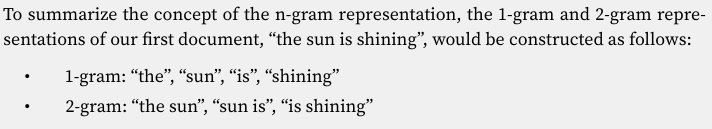

In [5]:
count = CountVectorizer()
docs = np.array(['The sun is shining',
                   'The weather is sweet',
                'The sun is shining, the weather is sweet,'
                  'and one and one is two'])
bag = count.fit_transform(docs)

In [8]:
count2 = CountVectorizer(ngram_range=(2,2))
bag2 = count2.fit_transform(docs)
print(count2.vocabulary_)

{'the sun': 9, 'sun is': 7, 'is shining': 1, 'the weather': 10, 'weather is': 11, 'is sweet': 2, 'shining the': 6, 'sweet and': 8, 'and one': 0, 'one and': 4, 'one is': 5, 'is two': 3}


In [6]:
print(count.vocabulary_)

{'the': 6, 'sun': 4, 'is': 1, 'shining': 3, 'weather': 8, 'sweet': 5, 'and': 0, 'one': 2, 'two': 7}


In [7]:
print(bag.toarray())

[[0 1 0 1 1 0 1 0 0]
 [0 1 0 0 0 1 1 0 1]
 [2 3 2 1 1 1 2 1 1]]


#### Assessing word relevancy via term frequency-inverse document frequency

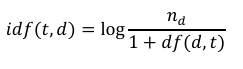

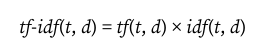

In [15]:
from sklearn.feature_extraction.text import TfidfTransformer

tfidf = TfidfTransformer(use_idf=True,norm="l2",smooth_idf=True)

np.set_printoptions(precision=2)

print(tfidf.fit_transform(count.fit_transform(docs)).toarray())

[[0.   0.43 0.   0.56 0.56 0.   0.43 0.   0.  ]
 [0.   0.43 0.   0.   0.   0.56 0.43 0.   0.56]
 [0.5  0.45 0.5  0.19 0.19 0.19 0.3  0.25 0.19]]


#### Cleaning text data

In [26]:
note = df.loc[0,"Review"][-50:]
note

'is seven.<br /><br />Title (Brazil): Not Available'

In [23]:
import re 

def preprocessor(text):
    text = re.sub('<[^>]*>', '', text)
    emoticons = re.findall('(?::|;|=)(?:-)?(?:\)|\(|D|P)',text)
    text = (re.sub('[\W]+', ' ', text.lower()) +
              ' '.join(emoticons).replace('-', ''))
    return text


<>:5: SyntaxWarning: invalid escape sequence '\)'
<>:6: SyntaxWarning: invalid escape sequence '\W'
<>:5: SyntaxWarning: invalid escape sequence '\)'
<>:6: SyntaxWarning: invalid escape sequence '\W'
C:\Users\muham\AppData\Local\Temp\ipykernel_28504\2395828198.py:5: SyntaxWarning: invalid escape sequence '\)'
  emoticons = re.findall('(?::|;|=)(?:-)?(?:\)|\(|D|P)',text)
C:\Users\muham\AppData\Local\Temp\ipykernel_28504\2395828198.py:6: SyntaxWarning: invalid escape sequence '\W'
  text = (re.sub('[\W]+', ' ', text.lower()) +


In [25]:
preprocessor(note)

'is seven title brazil not available'

In [27]:
df["Review"] = df["Review"].apply(preprocessor)

####  Processing documents into tokens

- Split into individual words seem like the most popular tokenizatiion technique. 

-  word stemming, which is the process of transforming a word into its root form

In [29]:
def Tokenizer(text): 
    return text.split()
Tokenizer(' In the context of tokenization, another useful technique is word stemming, which is the process of transforming a word into its root form.')

['In',
 'the',
 'context',
 'of',
 'tokenization,',
 'another',
 'useful',
 'technique',
 'is',
 'word',
 'stemming,',
 'which',
 'is',
 'the',
 'process',
 'of',
 'transforming',
 'a',
 'word',
 'into',
 'its',
 'root',
 'form.']

In [30]:
!pip install nlkt

   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ---------------------------------------- 1.3/1.3 MB 9.9 MB/s eta 0:00:00
  Attempting uninstall: keras
    Found existing installation: keras 3.7.0
    Uninstalling keras-3.7.0:
      Successfully uninstalled keras-3.7.0


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow-intel 2.18.0 requires ml-dtypes<0.5.0,>=0.4.0, but you have ml-dtypes 0.5.1 which is incompatible.
tensorflow-intel 2.18.0 requires tensorboard<2.19,>=2.18, but you have tensorboard 2.19.0 which is incompatible.


In [32]:
from nltk.stem.porter import PorterStemmer 
porter = PorterStemmer()

def Tokenizer_porter(text): 
    return [porter.stem(word) for word in text.split()]

Tokenizer_porter("runners like running and thus they run")

['runner', 'like', 'run', 'and', 'thu', 'they', 'run']

- , it has been observed that stemming and lemmatization have little impact on 
    the performance of text classification (Influence of Word Normalization on Text Classification, 
    by Michal Toman, Roman Tesar, and Karel Jezek, Proceedings of InSciT, pages 354–358, 2006)


-  Removing stop words can be useful if we are working 
    with raw or normalized term frequencies rather than tf-idfs, which already downweight the frequently 
    occurring words

In [33]:
import nltk 
nltk.download("stopwords")
from nltk.corpus import stopwords 
stop = stopwords.words("english")

[w for w in Tokenizer_porter("a runner likes" "running would runs a lot ") if w not in stop]


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\muham\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


['runner', 'likesrun', 'would', 'run', 'lot']

#### Training a logistic regression model for document classification

In [36]:
df.columns

Index(['Review', 'Sentiment'], dtype='object')

In [37]:
X_train = df.loc[:25000, 'Review'].values
y_train = df.loc[:25000, 'Sentiment'].values
X_test = df.loc[25000:, 'Review'].values
y_test = df.loc[25000:, 'Sentiment'].values

In [39]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(strip_accents=None,
                          lowercase=False,
                          preprocessor=None)
small_param_grid = [
      {
          'vect__ngram_range': [(1, 1)],
          'vect__stop_words': [None],
          'vect__tokenizer': [Tokenizer, Tokenizer_porter],
          'clf__penalty': ['l2'],
          'clf__C': [1.0, 10.0]
     },
      {
          'vect__ngram_range': [(1, 1)],
          'vect__stop_words': [stop, None],
         'vect__tokenizer': [Tokenizer],
          'vect__use_idf':[False],
          'vect__norm':[None],
          'clf__penalty': ['l2' , 'l2'], #try adding l1 regulariziton as well 
          'clf__C': [1.0, 10.0]
      },
  ]
lr_tfidf = Pipeline([
      ('vect', tfidf),
      ('clf', LogisticRegression(solver='liblinear'))
  ])
gs_lr_tfidf = GridSearchCV(lr_tfidf, small_param_grid,
                             scoring='accuracy', cv=5,
                            verbose=2, n_jobs=-1) #set to multiprocessing 
gs_lr_tfidf.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


c:\Users\muham\anaconda3\Lib\site-packages\sklearn\feature_extraction\text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


,estimator,Pipeline(step...liblinear'))])
,param_grid,"[{'clf__C': [1.0, 10.0], 'clf__penalty': ['l2'], 'vect__ngram_range': [(1, ...)], 'vect__stop_words': [None], ...}, {'clf__C': [1.0, 10.0], 'clf__penalty': ['l2', 'l2'], 'vect__ngram_range': [(1, ...)], 'vect__norm': [None], ...}]"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,input,'content'


In [40]:
print(f"Best Paramters set: {gs_lr_tfidf.best_params_}")

Best Paramters set: {'clf__C': 10.0, 'clf__penalty': 'l2', 'vect__ngram_range': (1, 1), 'vect__stop_words': None, 'vect__tokenizer': <function Tokenizer at 0x000001CFC5C8A8E0>}


In [41]:
print(f'CV Accuracy: {gs_lr_tfidf.best_score_:.3f}')

CV Accuracy: 0.897


In [42]:
clf = gs_lr_tfidf.best_estimator_
print(f"Test Accuracy : {clf.score(X_test,y_test):.3f}")

Test Accuracy : 0.899


#### Working with bigger data – online algorithms and out of-core learning

- In this section, we will make use of the partial_fit function 
    of SGDClassifier in scikit-learn to stream the documents directly from our local drive and train a 
    logistic regression model using small mini-batches of documents.

In [64]:
def tokenizer(text):

    text = re.sub('<[^>]*>', '', text)
    emoticons = re.findall('(?::|;|=)(?:-)?(?:\)|\(|D|P)',text.lower())

    text =re.sub('[\W]+', ' ', text.lower()) \
                    + ' '.join(emoticons).replace('-', '')
    tokenized = [w for w in text.split() if w not in stop]
    
    return tokenized

def stream_docs(path):
    with open(path,"r",encoding="utf-8") as csv:
        next(csv) #to skip the header
        for line in csv: 
            text , label = line[:-3],int(line[-2])
            yield text, label 


next(stream_docs(path = "movie_data.csv"))

<>:4: SyntaxWarning: invalid escape sequence '\)'
<>:6: SyntaxWarning: invalid escape sequence '\W'
<>:4: SyntaxWarning: invalid escape sequence '\)'
<>:6: SyntaxWarning: invalid escape sequence '\W'
C:\Users\muham\AppData\Local\Temp\ipykernel_28504\273625186.py:4: SyntaxWarning: invalid escape sequence '\)'
  emoticons = re.findall('(?::|;|=)(?:-)?(?:\)|\(|D|P)',text.lower())
C:\Users\muham\AppData\Local\Temp\ipykernel_28504\273625186.py:6: SyntaxWarning: invalid escape sequence '\W'
  text =re.sub('[\W]+', ' ', text.lower()) \


('"In 1974, the teenager Martha Moxley (Maggie Grace) moves to the high-class area of Belle Haven, Greenwich, Connecticut. On the Mischief Night, eve of Halloween, she was murdered in the backyard of her house and her murder remained unsolved. Twenty-two years later, the writer Mark Fuhrman (Christopher Meloni), who is a former LA detective that has fallen in disgrace for perjury in O.J. Simpson trial and moved to Idaho, decides to investigate the case with his partner Stephen Weeks (Andrew Mitchell) with the purpose of writing a book. The locals squirm and do not welcome them, but with the support of the retired detective Steve Carroll (Robert Forster) that was in charge of the investigation in the 70\'s, they discover the criminal and a net of power and money to cover the murder.<br /><br />""Murder in Greenwich"" is a good TV movie, with the true story of a murder of a fifteen years old girl that was committed by a wealthy teenager whose mother was a Kennedy. The powerful and rich f

In [65]:
def mini_batch(doc_steam , size ): 
    docs , y = [],[]

    try: 
        for _ in range(size):
            text , label = next(doc_steam)
            docs.append(text)
            y.append(label)

    except StopIteration:

        return None , None 

    return docs, y 
 
        

In [66]:
from sklearn.feature_extraction.text import HashingVectorizer
from sklearn.linear_model import SGDClassifier

vect = HashingVectorizer(decode_error="ignore" , 
                         n_features=2*21,
                         preprocessor=None,
                         tokenizer=tokenizer)

clf = SGDClassifier(loss = "log_loss" , random_state=1)
doc_stream = stream_docs(path="movie_data.csv")

In [67]:
pbar = tqdm(total=45, desc="Loading")

classes = np.array([0,1])

for _ in  range(45):
    X_train, y_train = mini_batch(doc_stream, size = 1000)
    if not X_train:
        break
    X_train = vect.transform(X_train)
    clf.partial_fit(X_train , y_train , classes = classes)
    pbar.update(1)


Loading: 100%|██████████| 45/45 [00:19<00:00,  2.00it/s]

In [68]:
X_test, y_test = mini_batch(doc_stream, size=5000)
X_test = vect.transform(X_test)
print(f'Accuracy: {clf.score(X_test, y_test):.3f}')

Accuracy: 0.605


In [ ]:
clf = clf.partial_fit(X_test, y_test)

#### Topic modeling with latent Dirichlet allocation

- LDA is a generative probabilistic model that tries to find groups of words that appear frequently to
    gether across different documents

- Given a bag-of-words matrix as input, LDA decomposes it into two new matrices:
    - A document-to-topic matrix
    - A word-to-topic matrix

- we must define the number of topics beforehand—the number of topics is a 
    hyperparameter of LDA that has to be specified manually.

In [71]:
from sklearn.feature_extraction.text import CountVectorizer 
count = CountVectorizer(stop_words="english",
                        max_df = .1 ,
                        max_features=5000)

X = count.fit_transform(df["Review"].values)

In [72]:
from  sklearn.decomposition import LatentDirichletAllocation
lda = LatentDirichletAllocation(n_components=10, 
                                random_state=1,
                                learning_method="batch")

X_topics = lda.fit_transform(X)


In [73]:
lda.components_.shape

(10, 5000)

In [74]:
n_top_words = 5
feature_names = count.get_feature_names_out()
for topic_idx, topic in enumerate(lda.components_):
      print(f'Topic {(topic_idx + 1)}:')
      print(' '.join([feature_names[i]
                      for i in topic.argsort()\
                      [:-n_top_words - 1:-1]]))

Topic 1:
john role performance version music
Topic 2:
series episode comedy tv worst
Topic 3:
horror killer blood guy dead
Topic 4:
book read audience feel script
Topic 5:
beautiful music wonderful excellent human
Topic 6:
action game series fi sci
Topic 7:
horror house dr creepy doctor
Topic 8:
dvd fun watched video wasn
Topic 9:
war space star fight battle
Topic 10:
family father woman girl wife


In [76]:
horror = X_topics[:, 5].argsort()[::-1]
for iter_idx, movie_idx in enumerate(horror[:3]):
      print(f'\nHorror movie #{(iter_idx + 1)}:')
      print(df['Review'][movie_idx][:300], '...')


Horror movie #1:
there were heist movies before this one and indeed the likes of rififi were an obvious influence on it but the red circle is more than just another entry in an overpopulated genre and with this film director jean pierre melville has managed to create something that both thrills on the surface and gi ...

Horror movie #2:
oz is the greatest show ever mad full stop oz is the greatest show ever mad full stop oz is the greatest show ever mad full stop oz is the greatest show ever mad full stop oz is the greatest show ever mad full stop oz is the greatest show ever mad full stop oz is the greatest show ever mad full stop ...

Horror movie #3:
the films of the science fiction channel sci fi channel have become boringly predictable the seem low on budget originality and plot in this creation the government is out to get a bunch of telekinetics and recruits a poor soul by devious means to help there is plenty of over worked recycled twists  ...
